# IMT4133 Data Science for Security and Forensics
## Assignment 3 - Transformer-Based Binary Classification

**Group 19**

**Members:** Marie Kjelaas, Abdishakur Bashir Adan, Linarte Andersen, Saba Ali

This notebook classifies network-flow records as **normal (0)** or **attack (1)** using the
encoder-only Transformer built in Lab 4. The work follows the three required tasks:

1. **Prepare the data** - clean it, split it, and turn each record into a sequence of tokens.
2. **Configure and train** - set up the Transformer with the required settings and train it for 10 epochs.
3. **Evaluate** - measure the best model on the test set and report the results.

The dataset file `Assignment_Data.csv` is **not** included in the submission, as required.


---
## Task 1 - Prepare the data

**The idea in plain terms.** A Transformer does not read a spreadsheet. It reads a *sentence* -
a sequence of tokens (words). So our job here is to turn every row of the dataset (one network
flow, with 42 numbers and categories) into a short "sentence" the model can read, after first
making sure the data is clean and honest.

Think of it like preparing ingredients before cooking: we throw out anything spoiled (impossible
values), remove exact duplicate portions, split the food into three plates (train / validation /
test) *before* seasoning so the taste test is fair, and finally write each dish out as a recipe
line the model can follow.

We keep the original file untouched and do all of this on a copy.


In [1]:
import re
import math
import random
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
import matplotlib.pyplot as plt

DATA_PATH = "Assignment_Data.csv"   # keep the dataset next to this notebook
SEED = 43

# keep the original untouched; work on a copy
original_df = pd.read_csv(DATA_PATH, low_memory=False)
df = original_df.copy()
print("Original data shape:", original_df.shape)

Original data shape: (20000, 45)


**Step 1 - Fix the target and pick the 42 input features.**
The target column `label` should only ever be `0` or `1`. A few rows carry other codes (2, 3, 9),
which are invalid, so we drop those rows. We also decide which columns the model is allowed to see:
everything *except* `id` (just a row number), `attack_cat` (a more detailed label - using it would
be cheating), and `label` itself (the answer). That leaves exactly **42 features**, kept in their
original column order.

In [2]:
# Step 1: clean the label, then choose the 42 input features
CATEGORICAL = ["proto", "service", "state"]
EXCLUDE = ["id", "attack_cat", "label"]

df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df[df["label"].isin([0, 1])].copy()
df["label"] = df["label"].astype(int)

feature_cols = [c for c in original_df.columns if c not in EXCLUDE]
numeric_cols = [c for c in feature_cols if c not in CATEGORICAL]
print("Number of input features:", len(feature_cols))
print("Categorical features:", CATEGORICAL)

Number of input features: 42
Categorical features: ['proto', 'service', 'state']


**Step 2 - Handle types and mark impossible values as missing.**
Three columns (`proto`, `service`, `state`) are categories (like "tcp", "ftp"), so we tidy the text:
trim spaces, lowercase it, and if it is blank we write the word `missing`. The dash `-` is a real
category here, so we keep it.

Every other feature should be a number. We convert each to a float, and anything that *cannot* be a
real measurement becomes "missing" (`NaN`) so we can fill it in properly later:
text where a number should be, infinity, negative values, and - for the two TTL fields `sttl`/`dttl`
- anything above 255 (a TTL is an 8-bit field, so 255 is its ceiling).

In [3]:
# Step 2: numeric -> float with impossible values marked missing; tidy categoricals
for col in numeric_cols:
    vals = pd.to_numeric(df[col], errors="coerce")   # non-numeric text -> NaN
    vals = vals.astype("float64")
    vals = vals.mask(np.isinf(vals))                 # +/- infinity -> NaN
    vals = vals.mask(vals < 0)                       # negatives -> NaN
    if col in ("sttl", "dttl"):
        vals = vals.mask(vals > 255)                 # TTL above 255 -> NaN
    df[col] = vals

def clean_categorical(series):
    s = series.astype("string").str.strip().str.lower()
    s = s.mask(s.isna() | (s == ""), "missing")      # missing / empty -> "missing"
    return s.astype(str)

for col in CATEGORICAL:
    df[col] = clean_categorical(df[col])

print("Missing values created (per feature, top 6):")
print(df[numeric_cols].isna().sum().sort_values(ascending=False).head(6))

Missing values created (per feature, top 6):
dpkts     5
rate      5
sbytes    5
sttl      5
dur       0
spkts     0
dtype: int64


**Step 3 - Remove repeats and contradictions (before filling anything in).**
First we drop rows that are *completely identical* across all 42 inputs **and** the label, keeping the
first copy - these add nothing. Then we remove any remaining rows that have the *same inputs but a
different label*: the data contradicts itself there, and we are told not to guess which label is right
(and not to peek at `attack_cat` to fix it). We do this *before* filling missing values, so filled-in
guesses never accidentally create or hide a duplicate.

In [4]:
# Step 3: remove exact duplicates, then contradictory rows (same inputs, different label)
key_cols = feature_cols + ["label"]
n_before = len(df)
df = df.drop_duplicates(subset=key_cols, keep="first").copy()
n_after_exact = len(df)

# any inputs that still repeat must now carry a different label -> a contradiction -> drop them
conflict_mask = df.duplicated(subset=feature_cols, keep=False)
df = df[~conflict_mask].copy()
n_after_conflict = len(df)

cleaned_count = len(df)
print("Exact duplicate rows removed:", n_before - n_after_exact)
print("Contradictory rows removed:", n_after_exact - n_after_conflict)
print("Cleaned records remaining:", cleaned_count)

Exact duplicate rows removed: 4480
Contradictory rows removed: 2
Cleaned records remaining: 15513


**Step 4 - Split 80/10/10, then fill gaps using only the training set.**
We split the rows into 80% training, 10% validation, 10% test. "Stratified" means each plate keeps the
same mix of normal vs attack as the whole dataset, so no split is unfairly easy or hard. We use
`random_state=43` both times so the split is identical every run, and we keep the row order that the
split returns (we do not re-sort the rows afterwards).

Then we fill the missing numbers with the **median** of each column - but the median is taken from the
**training set only**. This is the golden rule: the model must never learn anything (not even a median)
from the validation or test data, or the evaluation would be dishonestly optimistic.

In [5]:
# Step 4: stratified 80/10/10 split, then median-fill from the training set only
X = df[feature_cols].copy()
y = df["label"].copy()

# reserve 20%, then split that 20% equally into validation and test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# The data was in its original row order before splitting, and we keep the
# order train_test_split returns (we do not re-sort the splits afterwards).

# medians learned on the training set only, then applied to all three splits
train_medians = X_train[numeric_cols].median()
for part in (X_train, X_val, X_test):
    part[numeric_cols] = part[numeric_cols].fillna(train_medians)

print("Train / val / test sizes:", len(X_train), len(X_val), len(X_test))

Train / val / test sizes:

 12410 1551 1552


**Steps 5 & 6 - Turn each row into a token sequence, and build the vocabulary.**
Now we write each value as a single "word":
- a number like `31.0` becomes `number_31_0` (dots, minus and plus are spelled out so they survive);
- a category like `ftp-data` becomes `category_ftp_data` (odd characters become underscores).

Each feature is written as `feature = value`, and all 42 are joined into one line, e.g.
`dur = number_0_5 proto = category_tcp ...`. The lab tokenizer then splits that line into tokens.
Each feature gives 3 tokens (its name, the `=`, and its value), so **42 x 3 = 126 tokens** per record.

The **vocabulary** (the model's dictionary) is built from the **training records only**. We keep a token
only if it appears at least twice (rare one-offs are treated as "unknown"), number the tokens in the
order we first see them, and reserve `0` for padding and `1` for unknown. Finally every record is padded
out to a fixed length of **128** tokens, with an attention mask marking which positions are real (1) vs
padding (0).

In [6]:
# Step 5: how each value is written as a single token
def numeric_token(value):
    t = str(float(value)).replace(".", "_").replace("-", "minus").replace("+", "plus")
    return "number_" + t

def categorical_token(value):
    return "category_" + re.sub(r"[^0-9a-zA-Z_]", "_", str(value))

def row_to_text(row):
    parts = []
    for col in feature_cols:
        tok = categorical_token(row[col]) if col in CATEGORICAL else numeric_token(row[col])
        parts.append(f"{col} = {tok}")
    return " ".join(parts)

# the lab tokenizer
def tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", text.lower())

MAX_LEN = 128
PAD_ID, UNK_ID = 0, 1

train_texts = [row_to_text(r) for _, r in X_train.iterrows()]
val_texts   = [row_to_text(r) for _, r in X_val.iterrows()]
test_texts  = [row_to_text(r) for _, r in X_test.iterrows()]

print("Example record as text:")
print(train_texts[0][:160], "...")
print("Tokens in first record (before padding):", len(tokenize(train_texts[0])))

Example record as text:
dur = number_0_025746 proto = category_tcp service = category_smtp state = category_fin spkts = number_52_0 dpkts = number_42_0 sbytes = number_37232_0 dbytes = ...
Tokens in first record (before padding): 126


In [7]:
# Step 6: build the vocabulary from training only (keep tokens seen >= 2 times)
counts = {}
train_token_lists = []
for txt in train_texts:
    toks = tokenize(txt)
    train_token_lists.append(toks)
    for tk in toks:
        counts[tk] = counts.get(tk, 0) + 1

vocab = {"<pad>": PAD_ID, "<unk>": UNK_ID}
for toks in train_token_lists:
    for tk in toks:
        if counts[tk] >= 2 and tk not in vocab:
            vocab[tk] = len(vocab)
vocab_size = len(vocab)

def encode(text):
    ids = [vocab.get(tk, UNK_ID) for tk in tokenize(text)][:MAX_LEN]
    mask = [1] * len(ids)
    pad = MAX_LEN - len(ids)
    return ids + [PAD_ID] * pad, mask + [0] * pad

def encode_many(texts):
    ids_list, mask_list = [], []
    for t in texts:
        i, m = encode(t)
        ids_list.append(i); mask_list.append(m)
    return (torch.tensor(ids_list, dtype=torch.long),
            torch.tensor(mask_list, dtype=torch.long))

train_ids, train_mask = encode_many(train_texts)
val_ids,   val_mask   = encode_many(val_texts)
test_ids,  test_mask  = encode_many(test_texts)

y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_t   = torch.tensor(y_val.to_numpy(),   dtype=torch.long)
y_test_t  = torch.tensor(y_test.to_numpy(),  dtype=torch.long)

print("Encoded shapes:", train_ids.shape, val_ids.shape, test_ids.shape)
print("Vocabulary size (incl. PAD and UNK):", vocab_size)

Encoded shapes: torch.Size([12410, 128]) torch.Size([1551, 128]) torch.Size([1552, 128])
Vocabulary size (incl. PAD and UNK): 4489


### Task 1 - required counts

In [8]:
print("Cleaned records:", cleaned_count)
print("Training records:", len(train_texts))
print("Validation records:", len(val_texts))
print("Test records:", len(test_texts))
print("Vocabulary entries:", vocab_size)

Cleaned records: 15513
Training records: 12410
Validation records: 1551
Test records: 1552
Vocabulary entries: 4489


---
## Task 2 - Configure and train the Transformer

**The idea in plain terms.** The Transformer reads the 128-token "sentence" for a flow and has to
decide: normal or attack. It does this with **self-attention** - every token looks at every other
token and decides which ones matter for the decision - stacked **6 times** so the model can build up
from simple patterns to more complex ones. At the end it averages everything it understood (ignoring
the padding) and a final layer outputs two scores: one for "normal", one for "attack".

We reuse the exact Lab 4 building blocks and only change the required settings: **6 encoder blocks,
8 attention heads, embedding size 96, feed-forward size 192, sequence length 128, 2 output classes,
dropout 0.1**. Training uses **AdamW** (learning rate 0.0003, weight decay 0.01), **CrossEntropyLoss**,
batch size **32**, for **10 epochs**, with everything seeded to **43** so results are repeatable.

In [9]:
# ---- Lab 4 Transformer building blocks (reused) ----
class TokenAndPositionEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, max_len):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos_emb = nn.Embedding(max_len, d_model)
    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        return self.token_emb(x) + self.pos_emb(positions)

class SelfAttentionHead(nn.Module):
    def __init__(self, d_model, head_dim):
        super().__init__()
        self.Wq = nn.Linear(d_model, head_dim, bias=False)
        self.Wk = nn.Linear(d_model, head_dim, bias=False)
        self.Wv = nn.Linear(d_model, head_dim, bias=False)
        self.head_dim = head_dim
    def forward(self, x, attention_mask):
        q, k, v = self.Wq(x), self.Wk(x), self.Wv(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)
        key_mask = attention_mask.unsqueeze(1)
        scores = scores.masked_fill(key_mask == 0, torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores, dim=-1)
        return weights @ v, weights

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0
        head_dim = d_model // num_heads
        self.heads = nn.ModuleList(
            [SelfAttentionHead(d_model, head_dim) for _ in range(num_heads)])
        self.Wo = nn.Linear(d_model, d_model)
    def forward(self, x, attention_mask):
        outs = [h(x, attention_mask)[0] for h in self.heads]
        return self.Wo(torch.cat(outs, dim=-1))

class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(),
                                nn.Linear(d_ff, d_model))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, attention_mask):
        attn_output = self.attn(x, attention_mask)
        x = self.norm1(x + self.dropout(attn_output))
        ff_output = self.ff(x)
        x = self.norm2(x + self.dropout(ff_output))
        return x

class TinyTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, num_classes=2, d_model=96, num_heads=8,
                 d_ff=192, num_layers=6, max_len=128, dropout=0.1):
        super().__init__()
        self.embedding = TokenAndPositionEmbedding(vocab_size, d_model, max_len)
        self.blocks = nn.ModuleList(
            [TransformerEncoderBlock(d_model, num_heads, d_ff, dropout)
             for _ in range(num_layers)])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(d_model, num_classes)
    def forward(self, input_ids, attention_mask):
        x = self.embedding(input_ids)
        for blk in self.blocks:
            x = blk(x, attention_mask)
        mask = attention_mask.unsqueeze(-1).float()
        summed = (x * mask).sum(dim=1)
        pooled = summed / mask.sum(dim=1).clamp(min=1.0)   # masked mean pooling
        return self.classifier(self.dropout(pooled))

In [10]:
# required hyper-parameters
D_MODEL, N_HEADS, D_FF, N_LAYERS = 96, 8, 192, 6
NUM_CLASSES, DROPOUT = 2, 0.1
BATCH, EPOCHS, LR, WD = 32, 10, 3e-4, 0.01

class FlowDataset(Dataset):
    def __init__(self, ids, mask, labels):
        self.ids, self.mask, self.labels = ids, mask, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.ids[i], self.mask[i], self.labels[i]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def evaluate(model, loader, device):
    model.eval()
    correct = total = 0
    preds_all, labels_all = [], []
    with torch.no_grad():
        for ids, mask, labels in loader:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            logits = model(ids, mask)
            preds = logits.argmax(dim=-1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            preds_all += preds.cpu().tolist()
            labels_all += labels.cpu().tolist()
    return correct / total, preds_all, labels_all

**(a) Reset the seeds, build fresh loaders and a fresh model.**
After all the data inspection above, we reset every random seed to 43 and build brand-new data loaders
and a new model, so training starts from a clean, repeatable state. Only the training data is shuffled;
validation and test are kept in order. The loader's shuffling is also seeded to 43.

In [11]:
# (a) reset seeds, fresh loaders + fresh model
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(FlowDataset(train_ids, train_mask, y_train_t),
                          batch_size=BATCH, shuffle=True, num_workers=0,
                          drop_last=False, generator=g)
val_loader = DataLoader(FlowDataset(val_ids, val_mask, y_val_t),
                        batch_size=BATCH, shuffle=False, num_workers=0, drop_last=False)
test_loader = DataLoader(FlowDataset(test_ids, test_mask, y_test_t),
                         batch_size=BATCH, shuffle=False, num_workers=0, drop_last=False)

model = TinyTransformerClassifier(vocab_size, num_classes=NUM_CLASSES,
            d_model=D_MODEL, num_heads=N_HEADS, d_ff=D_FF,
            num_layers=N_LAYERS, max_len=MAX_LEN, dropout=DROPOUT).to(device)
print("Computing device:", device)

Computing device: cpu


**(b) Count the trainable parameters, then train for 10 epochs**, recording training and validation
accuracy after each epoch.

In [12]:
# (b) trainable parameter count
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", n_params)

Trainable parameters: 890402


In [13]:
# (b)+(c) train 10 epochs; keep the weights from the best validation epoch
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
criterion = nn.CrossEntropyLoss()

train_acc_hist, val_acc_hist = [], []
best_val, best_epoch, best_state = -1.0, None, None

for epoch in range(1, EPOCHS + 1):
    model.train()
    correct = total = 0
    for ids, mask, labels in train_loader:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(ids, mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        correct += (logits.argmax(dim=-1) == labels).sum().item()
        total += labels.size(0)
    tr_acc = correct / total
    va_acc, _, _ = evaluate(model, val_loader, device)
    train_acc_hist.append(tr_acc)
    val_acc_hist.append(va_acc)
    # strictly-greater keeps the earliest epoch on ties
    if va_acc > best_val:
        best_val, best_epoch = va_acc, epoch
        best_state = copy.deepcopy(model.state_dict())
    print(f"epoch {epoch:2d}  train_acc {tr_acc:.4f}  val_acc {va_acc:.4f}")

epoch  1  train_acc 0.8165  val_acc 0.9188


epoch  2  train_acc 0.9200  val_acc 0.9362


epoch  3  train_acc 0.9350  val_acc 0.9271


epoch  4  train_acc 0.9414  val_acc 0.9471


epoch  5  train_acc 0.9453  val_acc 0.9433


epoch  6  train_acc 0.9519  val_acc 0.9381


epoch  7  train_acc 0.9575  val_acc 0.9497


epoch  8  train_acc 0.9613  val_acc 0.9568


epoch  9  train_acc 0.9620  val_acc 0.9549


epoch 10  train_acc 0.9674  val_acc 0.9504


**(d) Report the best epoch and its validation accuracy.** We will restore these weights before
testing, so the epoch is chosen using validation data only - never the test set.

In [14]:
print(f"Best epoch: {best_epoch}")
print(f"Validation accuracy at best epoch: {best_val*100:.4f}%")

Best epoch: 8
Validation accuracy at best epoch: 95.6802%


---
## Task 3 - Evaluate on the test set

**The idea in plain terms.** We load back the best model (the one that did best on validation), put it in
evaluation mode (dropout off, no learning), and let it predict on the test set - data it has never seen.
We then score it four ways:
- **Accuracy** - of all flows, how many did it label correctly?
- **Precision** - of the flows it *called* attacks, how many really were? (few false alarms)
- **Recall** - of the real attacks, how many did it *catch*? (few misses)
- **F1** - the balance between precision and recall.

For a security tool, recall matters a lot (a missed attack is dangerous), but precision matters too
(too many false alarms and people stop trusting the alerts). The confusion matrix shows exactly where
the mistakes happen.

In [15]:
# restore the best checkpoint, then evaluate once on the test set
model.load_state_dict(best_state)
test_acc, test_preds, test_labels = evaluate(model, test_loader, device)

prec = precision_score(test_labels, test_preds, average="binary", pos_label=1, zero_division=0)
rec  = recall_score(test_labels, test_preds, average="binary", pos_label=1, zero_division=0)
f1   = f1_score(test_labels, test_preds, average="binary", pos_label=1, zero_division=0)

print(f"Test accuracy:  {test_acc*100:.4f}%")
print(f"Test precision: {prec*100:.4f}%")
print(f"Test recall:    {rec*100:.4f}%")
print(f"Test F1:        {f1*100:.4f}%")

Test accuracy:  94.0077%
Test precision: 95.4545%
Test recall:    90.4903%
Test F1:        92.9062%


### Results table (percentages to 4 decimal places)

In [16]:
results_table = pd.DataFrame({
    "Metric": ["Best epoch", "Validation accuracy at best epoch",
               "Test accuracy", "Test precision", "Test recall", "Test F1"],
    "Value": [f"{best_epoch}",
              f"{best_val*100:.4f}%",
              f"{test_acc*100:.4f}%",
              f"{prec*100:.4f}%",
              f"{rec*100:.4f}%",
              f"{f1*100:.4f}%"]
})
results_table

,Metric,Value
0,Best epoch,8
1,Validation accuracy at best epoch,95.6802%
2,Test accuracy,94.0077%
3,Test precision,95.4545%
4,Test recall,90.4903%
5,Test F1,92.9062%


### Confusion matrix (rows = true label, columns = predicted label; order 0, 1)

In [17]:
cm = confusion_matrix(test_labels, test_preds, labels=[0, 1])
cm_df = pd.DataFrame(cm,
                     index=["true 0 (normal)", "true 1 (attack)"],
                     columns=["pred 0 (normal)", "pred 1 (attack)"])
cm_df

,pred 0 (normal),pred 1 (attack)
true 0 (normal),850,29
true 1 (attack),64,609


### Training and validation accuracy across the 10 epochs

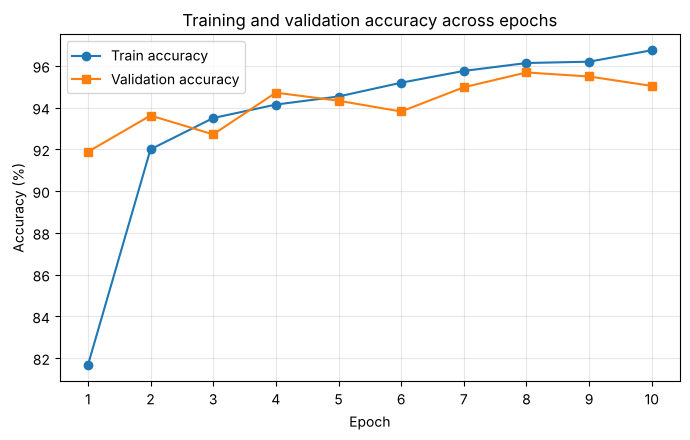

In [18]:
epochs_axis = list(range(1, EPOCHS + 1))
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_axis, [a*100 for a in train_acc_hist], marker="o", label="Train accuracy")
plt.plot(epochs_axis, [a*100 for a in val_acc_hist], marker="s", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)")
plt.title("Training and validation accuracy across epochs")
plt.xticks(epochs_axis); plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

### Computing device and PyTorch version

In [19]:
print("Computing device used:", device)
print("PyTorch version:", torch.__version__)

Computing device used: cpu
PyTorch version: 2.14.1+cu130


---
## Short summary of results

The Lab 4 Transformer was reused unchanged except for the required settings (6 encoder blocks,
8 attention heads, embedding size 96, feed-forward size 192, sequence length 128, 2 output classes,
dropout 0.1).

**Task 1 (data).** After dropping 5 invalid-label rows, 4,480 exact duplicate rows and 2 contradictory
rows, **15,513** clean records remained. These were split 80/10/10 into **12,410** training, **1,551**
validation and **1,552** test records. Each flow was written as a 126-token sentence padded to 128,
using a training-only vocabulary of **4,489** entries.

**Task 2 (training).** The model has **890,402** trainable parameters. Trained for 10 epochs with AdamW
(lr 0.0003, weight decay 0.01), the highest validation accuracy was reached at **epoch 8**
(validation accuracy **95.6802%**).

**Task 3 (evaluation on the held-out test set).**

| Result | Value |
|---|---|
| Best epoch | 8 |
| Validation accuracy at best epoch | 95.6802% |
| Test accuracy | 94.0077% |
| Test precision | 95.4545% |
| Test recall | 90.4903% |
| Test F1-score | 92.9062% |

Confusion matrix (test set): of 879 normal flows, 850 were correct and 29 were false alarms; of 673
attacks, 609 were caught and 64 were missed. Precision is a little above recall here, meaning few false
alarms at the cost of a few more missed attacks.

Computing device: **CPU**. PyTorch version: **2.14.1**. All figures are reproduced by restarting the
kernel and running the notebook top to bottom.
